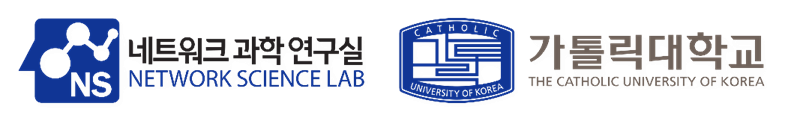

# Week 10: Graph Transformers

A GNN only exchanges messages along the edges. It is at most as powerful as 1-WL, and information from far away has to squeeze through many layers. A Transformer lets every token attend to every other token in one layer, but it knows nothing about the graph. A Transformer into three parts: what are the tokens, how does the structure get in, and who attends to whom?

| Model | Tokens | How the structure gets in | Who attends to whom | Attention cost |
|:--|:--|:--|:--|:--|
| **GT** | nodes | LapPE in the input, edge features in the scores | neighbours | $O(m)$ |
| **Graphormer** | nodes + [VNode] | degree in the input, distance and edge biases in the scores | all pairs | $O(n^2)$ |
| **GraphGPS** | nodes | PE/SE in the input, an MPNN in parallel | all pairs | $O(n^2)$, or $O(n)$ with linear attention |
| **TokenGT** | nodes + edges + [graph] | node and type identifiers in the tokens | all pairs of tokens | $O((n+m)^2)$ |
| **Exphormer** | nodes + virtual node | a sparse interaction graph | edges of that graph | $O(n+m)$ |
| **HGT** | typed nodes | weights that depend on the node and edge types | neighbours | $O(m)$ |

## Table of contents
- [0. Setup](#0-setup)
- [1. Encodings: how much of the graph does a model see?](#1-encodings-how-much-of-the-graph-does-a-model-see)
- [2. Attention is message passing](#2-attention-is-message-passing)
- [3. ZINC: dense batches, training, baseline](#3-zinc-dense-batches-training-baseline)
- [4. GT: neighbourhood attention + LapPE](#4-gt-neighbourhood-attention--lappe)
- [5. Graphormer: structure inside the attention](#5-graphormer-structure-inside-the-attention)
- [6. GraphGPS: local + global](#6-graphgps-local--global)
- [7. TokenGT: nodes and edges as tokens](#7-tokengt-nodes-and-edges-as-tokens)
- [8. Exphormer: sparse attention on an expander](#8-exphormer-sparse-attention-on-an-expander)
- [9. HGT: heterogeneous graphs](#9-hgt-heterogeneous-graphs)
- [10. Summary](#10-summary)

# 0. Setup

In [14]:
INSTALL_DEPENDENCIES = False

if INSTALL_DEPENDENCIES:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "torch-geometric"])

In [15]:
import math, time, random, copy, warnings, contextlib, io, tempfile
from types import SimpleNamespace
warnings.filterwarnings("ignore")                
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.datasets import ZINC, DBLP

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(0)
ROOT = f"{tempfile.gettempdir()}/pyg_datasets"

# One colour per model, reused in every figure.
MODEL_COLORS = {"GINE": "#7a7a7a", "GT": "#2a78d6", "Graphormer": "#eb6834", "GPS": "#1baf7a",
                "TokenGT": "#eda100", "Exphormer": "#e87ba4"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

Device: cuda


# 1. Encodings: how much of the graph does a model see?

If the tokens are the nodes, the adjacency is lost, so a graph transformer has to get the structure back through encodings:

| Scope | Examples | What it tells the model | Used by |
|:--|:--|:--|:--|
| Local | node degree, random-walk return probabilities (RWSE) | what the neighbourhood looks like | Graphormer, GPS, Exphormer |
| Global | Laplacian eigenvectors (LapPE) | where the node sits in the whole graph | GT, TokenGT |
| Relative | shortest-path distance, edge features along the path | how nodes $i$ and $j$ relate | Graphormer |

## 1.1. Distances beat 1-WL

An MPNN is at most as powerful as the 1-WL test: every node repeatedly combines its colour with the colours of its neighbours. Two graphs that 1-WL cannot tell apart, although the left one has two squares and the right one two triangles. Their shortest-path distances (SPD) do differ, and these distances are what Graphormer feeds into its attention.

In [16]:
def from_edges(edges):
    """Dense adjacency matrix of an undirected graph given by its list of edges."""
    n = max(map(max, edges)) + 1
    A = torch.zeros(n, n, dtype=torch.long)
    for u, v in edges:
        A[u, v] = A[v, u] = 1
    return A

def wl_colors(A, rounds=None):
    """1-WL colour refinement. A colour is a hash of (own colour, sorted colours of the neighbours), so the
    colours of two different graphs can be compared."""
    n = len(A)
    neighbours = [A[i].nonzero().view(-1).tolist() for i in range(n)]
    colors = [0] * n
    for _ in range(rounds or n):
        colors = [hash((colors[i], tuple(sorted(colors[j] for j in neighbours[i])))) for i in range(n)]
    return colors

def shortest_paths(E, max_hops=5):
    """All-pairs shortest paths of a batch of graphs (Floyd-Warshall on dense tensors).
    E [G, N, N]: edge types, 0 = no edge. Returns
      spd  [G, N, N]: number of hops (1000 or more when there is no path),
      path [G, N, N, max_hops]: edge types along one shortest path, 0 after its end."""
    G, N = E.shape[:2]
    nodes = torch.arange(N)
    spd = torch.where(E > 0, 1, 1000)
    spd[:, nodes, nodes] = 0
    next_hop = nodes.expand(G, N, N).clone()                  # next_hop[g, i, j]: first step on the way from i to j
    for k in nodes:
        via_k = spd[:, :, k, None] + spd[:, k, None, :]
        shorter = via_k < spd
        spd = torch.where(shorter, via_k, spd)
        next_hop = torch.where(shorter, next_hop[:, :, k, None], next_hop)
    g, ends = torch.arange(G)[:, None, None], nodes.expand(N, N)
    here, path = nodes[:, None].expand(G, N, N), []
    for _ in range(max_hops):                                 # walk along the next_hop pointers
        hop = next_hop[g, here, ends]
        path.append(E[g, here, hop])
        here = hop
    return spd, torch.stack(path, -1)

In [17]:
squares = from_edges([(0, 1), (1, 2), (3, 4), (4, 5), (0, 3), (1, 4), (2, 5)])       
triangles = from_edges([(0, 1), (0, 2), (1, 2), (2, 3), (3, 4), (3, 5), (4, 5)])     

print('Same 1-WL colours:', sorted(wl_colors(squares)) == sorted(wl_colors(triangles)))
for name, A in (('left ', squares), ('right', triangles)):
    spd, _ = shortest_paths(A[None])
    print(f'SPD sets of the {name} graph:', sorted({tuple(sorted(row)) for row in spd[0].tolist()}))

Same 1-WL colours: True
SPD sets of the left  graph: [(0, 1, 1, 1, 2, 2), (0, 1, 1, 2, 2, 3)]
SPD sets of the right graph: [(0, 1, 1, 1, 2, 2), (0, 1, 1, 2, 3, 3)]


The nodes of degree 2 have the set $\{0, 1, 1, 2, 2, 3\}$ on the left and $\{0, 1, 1, 2, 3, 3\}$ on the right.

## 1.2. Laplacian eigenvectors

$L = D - A$ encodes the graph, and an eigenvector ($Lv = \lambda v$) has one entry per node, so it can be fed to a Transformer. LapPE stacks the $k$ eigenvectors with the smallest non-zero eigenvalues: the $i$-th row is the positional encoding of node $i$.

For a unit eigenvector, $\lambda = v^\top L v = \sum_{(i,j) \in E} (v_i - v_j)^2$. A small $\lambda$ therefore means that $v$ changes slowly along the edges. Let's look at four eigenvectors of a small molecule.

In [18]:
def laplacian(A, normalized=False):
    """L = D - A, or the normalised Laplacian I - D^{-1/2} A D^{-1/2}."""
    d = A.sum(-1)
    if not normalized:
        return torch.diag(d) - A
    s = d.clamp(min=1).pow(-0.5)
    return torch.eye(len(A), dtype=A.dtype) - s[:, None] * A * s[None, :]

def lap_pe(A, k):
    """LapPE: the k eigenvectors of L with the smallest non-zero eigenvalues (the constant eigenvector is dropped).
    Row i is the encoding of node i; graphs with too few nodes are padded with zeros."""
    _, U = torch.linalg.eigh(laplacian(A.double()))
    return F.pad(U[:, 1:k + 1].float(), (0, max(k + 1 - len(A), 0)))

def rw_se(A, k):
    """RWSE: chance that a random walk from node i is back at i after 1, ..., k steps, diag((D^{-1}A)^m).
    Works on one graph [N, N] or on a batch [G, N, N]."""
    P = A / A.sum(-1, keepdim=True).clamp(min=1)
    Pm, se = P, []
    for _ in range(k):
        se.append(Pm.diagonal(dim1=-2, dim2=-1))
        Pm = Pm @ P
    return torch.stack(se, -1)

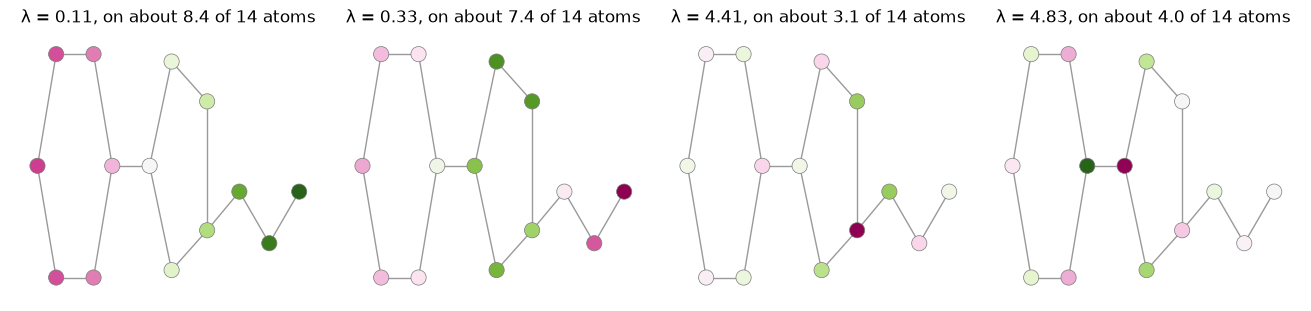

In [19]:
molecule = from_edges([(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 0),               # a 6-ring
                       (5, 6),                                                       # a bond
                       (6, 7), (7, 8), (8, 9), (9, 10), (10, 6),                     # a 5-ring
                       (8, 11), (11, 12), (12, 13)])                                 # a chain
lam, U = torch.linalg.eigh(laplacian(molecule.double()))
n, G = len(molecule), nx.from_numpy_array(molecule.numpy())

def on_circle(nodes, center, radius, start, direction=1):
    """Drawing positions for the nodes of one ring."""
    angles = np.deg2rad(start + direction * 360 / len(nodes) * np.arange(len(nodes)))
    return {v: (center + radius * np.cos(a), radius * np.sin(a)) for v, a in zip(nodes, angles)}

pos = (on_circle([5, 0, 1, 2, 3, 4], 0, 1, 0) | on_circle([6, 7, 8, 9, 10], 2.85, 0.85, 180)
       | {11: (4.4, -0.2), 12: (5.2, -0.6), 13: (6, -0.2)})

fig, axes = plt.subplots(1, 4, figsize=(13, 3), constrained_layout=True)
for ax, k in zip(axes, (1, 2, n - 2, n - 1)):
    v = U[:, k].numpy()
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#9a9a9a")
    nodes = nx.draw_networkx_nodes(G, pos, ax=ax, node_color=v, cmap="PiYG", vmin=-abs(v).max(), vmax=abs(v).max(),
                                   node_size=120, edgecolors="#7a7a7a", linewidths=0.5)
    ax.set_title(f"λ = {lam[k]:.2f}, on about {1 / (v ** 4).sum():.1f} of {n} atoms")   # effective number of atoms
    ax.set_axis_off()
plt.show()

* The eigenvectors with small $\lambda$ vary slowly over the whole molecule: the first one separates the left part from the right part. They say where an atom sits globally.
* The eigenvectors with large $\lambda$ change sign between neighbours and live on a few atoms around a branching point. They describe local detail.

One problem: if $v$ is an eigenvector, so is $-v$, and the sign that `eigh` returns is arbitrary. The models flip the signs at random during training (`random_signs`) so that they do not learn it.

## 1.3. Random-walk encoding

RWSE records the chance that a random walk is back at its start after $m$ steps: $\text{diag}((D^{-1}A)^m)$, $m = 1, \dots, k$. It needs no eigendecomposition and has no sign problem. A walk can only close after an odd number of steps if it goes around an odd cycle, so RWSE sees rings, which is why it is strong on tasks that need cycles:

In [20]:
atoms = {'atom in the 6-ring': 2, 'atom in the 5-ring': 8, 'end of the chain': 13}
pd.DataFrame(rw_se(molecule.float(), 8)[list(atoms.values())].numpy(), index=list(atoms),
             columns=[f'{m} steps' for m in range(1, 9)]).round(3)

,1 steps,2 steps,3 steps,4 steps,5 steps,6 steps,7 steps,8 steps
atom in the 6-ring,0.0,0.5,0.0,0.375,0.000,0.323,0.000,0.292
atom in the 5-ring,0.0,0.5,0.0,0.361,0.028,0.297,0.047,0.259
end of the chain,0.0,0.5,0.0,0.375,0.000,0.302,0.000,0.253


Only the atom of the 5-ring has a non-zero entry after 5 steps. The atom of the 6-ring and the atom of the chain have zeros at every odd step, but they differ at the even steps.

## 1.4. Who can tell what apart?

Comparing the encodings on two classic examples:

* the circular skip-link graphs $\mathcal{G}_{\text{skip}}(n, R)$: a cycle of $n$ nodes plus an edge from every node $i$ to $i + R$. All of them are 4-regular, so 1-WL gives every node the same colour;
* decalin (two 6-rings sharing a bond) and bicyclopentyl (two 5-rings joined by a bond), the classic pair of molecules that 1-WL confuses.

To compare two graphs we need descriptors that do not depend on the node order. For LapPE we use the eigenvalues, because the eigenvectors themselves are ambiguous.

In [21]:
def csl(n, skip):
    """Circular skip-link graph G_skip(n, skip)."""
    return from_edges([(i, (i + s) % n) for i in range(n) for s in (1, skip)])

decalin = from_edges([(0, 1), (0, 2), (2, 3), (3, 4), (4, 5), (5, 1), (0, 6), (6, 7), (7, 8), (8, 9), (9, 1)])
bicyclopentyl = from_edges([(0, 1), (0, 2), (2, 3), (3, 4), (4, 5), (5, 0), (1, 6), (6, 7), (7, 8), (8, 9), (9, 1)])

descriptors = {
    '1-WL': lambda A: sorted(wl_colors(A)),
    'RWSE': lambda A: sorted(map(tuple, rw_se(A.float(), 16).numpy().round(5).tolist())),
    'SPD': lambda A: sorted(map(tuple, shortest_paths(A[None])[0][0].sort(1).values.tolist())),
    'Laplacian spectrum': lambda A: torch.linalg.eigvalsh(laplacian(A.double())).numpy().round(5).tolist()}
pairs = {'squares / triangles': (squares, triangles),
         'G_skip(11, 2) / G_skip(11, 3)': (csl(11, 2), csl(11, 3)),
         'decalin / bicyclopentyl': (decalin, bicyclopentyl)}

pd.DataFrame({name: {pair: 'different' if f(A) != f(B) else 'same' for pair, (A, B) in pairs.items()}
              for name, f in descriptors.items()})

,1-WL,RWSE,SPD,Laplacian spectrum
squares / triangles,same,different,different,different
"G_skip(11, 2) / G_skip(11, 3)",same,different,different,different
decalin / bicyclopentyl,same,different,different,different


1-WL fails on all three pairs, and every encoding separates them. Comparing the encodings inside one graph. Below we group the atoms of decalin that receive the same encoding.

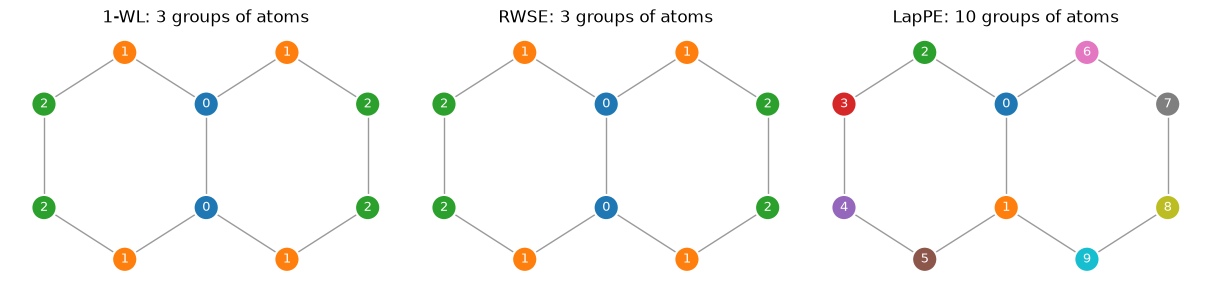

In [22]:
def groups(rows):
    """Number the groups of identical rows."""
    seen = {}
    return [seen.setdefault(tuple(row), len(seen)) for row in rows]

encodings = {'1-WL': groups([[c] for c in wl_colors(decalin)]),
             'RWSE': groups(rw_se(decalin.float(), 16).numpy().round(5).tolist()),
             'LapPE': groups(lap_pe(decalin, 9).numpy().round(5).tolist())}

G = nx.from_numpy_array(decalin.numpy())
pos = on_circle([0, 2, 3, 4, 5, 1], -0.87, 1, 30) | on_circle([0, 6, 7, 8, 9, 1], 0.87, 1, 150, direction=-1)
fig, axes = plt.subplots(1, 3, figsize=(12, 2.8), constrained_layout=True)
for ax, (name, group) in zip(axes, encodings.items()):
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#9a9a9a")
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[plt.cm.tab10(g) for g in group], node_size=330,
                           edgecolors="white", linewidths=1.5)
    nx.draw_networkx_labels(G, pos, ax=ax, labels=dict(enumerate(group)), font_size=9, font_color="white")
    ax.set_title(f"{name}: {max(group) + 1} groups of atoms")
    ax.set_axis_off()
plt.show()

1-WL and RWSE put the atoms in the same 3 groups: atoms that play the same structural role look identical. 

LapPE gives all 10 atoms different vectors: it is a positional encoding, so even atoms that are mirror images of each other get different positions. 

That is the difference between the two kinds of encoding: a structural encoding says what a node looks like, a positional encoding says where it is.

# 2. Attention is message passing

Comparing one layer of a GNN and of a Transformer:

$$\text{GNN:}\quad h_i^{\ell+1} = \sigma\Big(U^\ell h_i^\ell + \sum_{j \in \mathcal{N}(i)} V^\ell h_j^\ell\Big)
\qquad\qquad \text{Transformer:}\quad h_i^{\ell+1} = \sum_{j \in S} w_{ij}\, V^\ell h_j^\ell,\quad w_{ij} = \text{softmax}_j(Q^\ell h_i^\ell \cdot K^\ell h_j^\ell)$$

Both are a weighted sum of messages from a set of nodes. The Transformer computes the weights from the features, and its set $S$ is every token: self-attention is message passing on the complete graph. So we can implement attention in two ways:

* `DenseAttention`: the usual matrix form, $O(N^2)$ for a graph of $N$ nodes. Graphormer, GPS and TokenGT use it.
* `EdgeAttention`: message passing along an edge list, $O(E)$. GT and Exphormer use it. With edge features, the score of an edge is multiplied by the edge vector, as in GT.

`edge_softmax` is the softmax for several heads.

In [23]:
def edge_softmax(scores, targets, n):
    """Softmax of the scores [E, H] of the edges over the incoming edges of each target node (one softmax per head)."""
    m = scores.new_full((n, scores.size(1)), -math.inf)
    m = m.scatter_reduce(0, targets[:, None].expand_as(scores), scores.detach(), 'amax')     # for numerical stability
    e = (scores - m[targets]).exp()
    return e / torch.zeros_like(m).index_add_(0, targets, e)[targets]


class DenseAttention(nn.Module):
    """Multi-head attention on a padded batch h [B, N, d]: cost O(N²) for every graph.
        e_ij = (W_Q h_i)·(W_K h_j) / sqrt(d_k) + bias_ij,   α_ij = softmax_j(e_ij),   out_i = O(‖_heads Σ_j α_ij W_V h_j)
    `allowed` [B, N, N] says which j each node i may attend to; `bias` [B, H, N, N] is an optional structural bias."""
    def __init__(self, dim, heads):
        super().__init__()
        self.H, self.d_k = heads, dim // heads
        self.qkv, self.O = nn.Linear(dim, 3 * dim, bias=False), nn.Linear(dim, dim)

    def forward(self, h, allowed, bias=None):
        B, N, _ = h.shape
        q, k, v = self.qkv(h).view(B, N, 3, self.H, self.d_k).permute(2, 0, 3, 1, 4)      # each [B, H, N, d_k]
        e = q @ k.transpose(-1, -2) / self.d_k ** 0.5                                     # [B, H, N, N]
        if bias is not None:
            e = e + bias
        allowed = allowed | torch.diag_embed(~allowed.any(-1))                            # padding attends to itself
        self.alpha = e.masked_fill(~allowed[:, None], -math.inf).softmax(-1)
        return self.O((self.alpha @ v).transpose(1, 2).flatten(2))


class EdgeAttention(nn.Module):
    """The same attention as message passing along an edge list (j -> i): cost O(E).
    h [n, d] is a flat list of nodes. With edge features e [E, d]:
        ŵ_ij = (W_Q h_i ⊙ W_K h_j) / sqrt(d_k) ⊙ W_E e_ij,    α_ij = softmax_j(Σ_l ŵ_ij,l)
    Returns the new node vectors and the edge scores ŵ, which GT uses to update the edge features."""
    def __init__(self, dim, heads, use_edges=False):
        super().__init__()
        self.H, self.d_k = heads, dim // heads
        self.qkv, self.O = nn.Linear(dim, 3 * dim, bias=False), nn.Linear(dim, dim)
        self.E = nn.Linear(dim, dim, bias=False) if use_edges else None

    def forward(self, h, src, dst, e=None):
        q, k, v = self.qkv(h).view(len(h), 3, self.H, self.d_k).unbind(1)                 # each [n, H, d_k]
        w = q[dst] * k[src] / self.d_k ** 0.5                                             # [E, H, d_k]
        if self.E is not None:
            w = w * self.E(e).view(-1, self.H, self.d_k)
        self.alpha = edge_softmax(w.sum(-1), dst, len(h))                                 # [E, H]
        out = torch.zeros_like(v).index_add_(0, dst, self.alpha[..., None] * v[src])      # [n, H, d_k]
        return self.O(out.flatten(1)), w.flatten(1)

Check the claim numerically: with the same weights, `EdgeAttention` on the complete graph must give the same result as `DenseAttention` on all pairs, and the same must hold on any other graph, here a ring.

In [24]:
set_seed(0)
n, dim, heads = 7, 64, 4
h = torch.randn(1, n, dim)
dense_attn, edge_attn = DenseAttention(dim, heads), EdgeAttention(dim, heads)
edge_attn.load_state_dict(dense_attn.state_dict())

complete, ring = torch.ones(n, n, dtype=torch.bool), csl(n, 1) > 0
for name, A in (('complete graph', complete), ('ring', ring)):
    dst, src = A.nonzero(as_tuple=True)
    difference = dense_attn(h, A[None])[0] - edge_attn(h[0], src, dst)[0]
    print(f'{name:<15} {len(src):3d} edges, largest difference between the two forms: {difference.abs().max():.1e}')

perm = torch.randperm(n)
difference = dense_attn(h[:, perm], complete[None]) - dense_attn(h, complete[None])[:, perm]
print(f'Permuting the input only permutes the output (equivariance), largest difference: {difference.abs().max():.1e}')

complete graph   49 edges, largest difference between the two forms: 8.9e-08
ring             14 edges, largest difference between the two forms: 1.2e-07
Permuting the input only permutes the output (equivariance), largest difference: 1.2e-07


The two forms agree up to rounding errors. The last line is the reason we need encodings: without them, attention treats the nodes as a set.

# 3. ZINC: dense batches, training, baseline
## 3.1. Dense batches

Comparing the molecular models on ZINC, as in the sample code: 12,000 molecules, and the task is to predict one number per molecule (lower MAE is better). Molecules are small, so we can store each one as a padded dense tensor and compute every encoding once: `DenseGraphs` keeps the whole dataset on the device, and a mini-batch is only a slice of it. Each batch gives both views of the graphs: flat lists of nodes and edges for `EdgeAttention`, dense pairs for `DenseAttention`.

In [25]:
def regular_expander(n, degree, rng):
    """Random d-regular multigraph: the union of d/2 random permutations i -> π(i), as in Exphormer. Returns its
    adjacency matrix with multiplicities (loops count twice), so that it is exactly d-regular."""
    A = np.zeros((n, n))
    for _ in range(degree // 2):
        A[np.arange(n), rng.permutation(n)] += 1
    return A + A.T

def random_expander(n, degree, rng):
    """The same graph as boolean matrix of edges for the attention (no multi-edges, no loops)."""
    A = torch.as_tensor(regular_expander(n, degree, rng)) > 0
    return A & ~torch.eye(n, dtype=torch.bool)

In [26]:
class DenseGraphs:
    """A set of small graphs as padded dense tensors, with all their encodings pre-computed once.
    With G graphs and N the size of the largest one:
        x    [G, N]         node type                 mask [G, N]        True for the real nodes
        E    [G, N, N]      edge type, 0 = no edge    y    [G]           target
        lap  [G, N, k_lap]  LapPE                     rwse [G, N, k_rw]  RWSE
        ids  [G, N, d_p]    eigenvectors of the normalised Laplacian (identifiers of TokenGT)
        spd  [G, N, N]      shortest-path distance    path [G, N, N, max_hops]  edge types along the shortest path
        exp  [G, N, N]      random expander graph (Exphormer)
    batches() crops all this to the largest graph of the batch, and also lists the nodes and edges in flat form."""
    def __init__(self, graphs, k_lap=8, k_rw=16, max_hops=5, d_p=37, expander_degree=4, seed=0):
        """graphs: list of (x [n], E [n, n], y)."""
        G, N = len(graphs), max(len(x) for x, _, _ in graphs)
        rng = np.random.default_rng(seed)
        x, E = torch.zeros(G, N, dtype=torch.long), torch.zeros(G, N, N, dtype=torch.long)
        mask, exp = torch.zeros(G, N, dtype=torch.bool), torch.zeros(G, N, N, dtype=torch.bool)
        lap, ids = torch.zeros(G, N, k_lap), torch.zeros(G, N, d_p)
        for g, (xg, Eg, _) in enumerate(graphs):
            n, A = len(xg), (Eg > 0).float()
            x[g, :n], E[g, :n, :n], mask[g, :n] = xg, Eg, True
            lap[g, :n] = lap_pe(A, k_lap)
            ids[g, :n, :n] = torch.linalg.eigh(laplacian(A.double(), normalized=True))[1].float()
            exp[g, :n, :n] = random_expander(n, expander_degree, rng)
        spd, path = shortest_paths(E, max_hops)
        self.size = G
        self.x, self.mask, self.lap, self.ids, self.exp = x, mask, lap, ids, exp
        self.y = torch.stack([y for _, _, y in graphs])
        self.E, self.spd, self.path = E.byte(), spd.clamp(max=255).byte(), path.byte()   # one byte is enough
        self.rwse, self.degree = rw_se((E > 0).float(), k_rw), (E > 0).sum(-1)
        vars(self).update({k: v.to(device) for k, v in vars(self).items() if torch.is_tensor(v)})

    def __len__(self):
        return self.size

    def batches(self, batch_size, shuffle=False):
        order = torch.randperm(self.size) if shuffle else torch.arange(self.size)
        for idx in order.to(device).split(batch_size):
            N = self.mask[idx].sum(1).max()
            mask, E = self.mask[idx, :N], self.E[idx, :N, :N].long()
            flat = mask.view(-1).cumsum(0).view(mask.shape) - 1           # position of each real node in the flat list
            g, i, j = E.nonzero(as_tuple=True)
            gx, ix, jx = self.exp[idx, :N, :N].nonzero(as_tuple=True)
            yield SimpleNamespace(
                B=len(idx), n=int(mask.sum()), mask=mask, y=self.y[idx], gid=mask.nonzero()[:, 0],  # graph of each node
                x=self.x[idx, :N][mask], degree=self.degree[idx, :N][mask],                         # flat nodes
                lap=self.lap[idx, :N][mask], rwse=self.rwse[idx, :N][mask], ids=self.ids[idx, :N][mask],
                src=flat[g, j], dst=flat[g, i], edge_type=E[g, i, j],                               # flat edges j -> i
                exp_src=flat[gx, jx], exp_dst=flat[gx, ix],
                E=E, spd=self.spd[idx, :N, :N].long(), path=self.path[idx, :N, :N].long(),          # dense pairs
                allowed=mask[:, None] & mask[:, :, None])                                           # all real pairs

def load_zinc(split, **kwargs):
    with contextlib.redirect_stderr(io.StringIO()), contextlib.redirect_stdout(io.StringIO()):   # hide the download log
        dataset = ZINC(f"{ROOT}/ZINC", subset=True, split=split)
    graphs = []
    for d in dataset:
        x = d.x.view(-1)
        E = torch.zeros(len(x), len(x), dtype=torch.long)
        E[d.edge_index[0], d.edge_index[1]] = d.edge_attr
        graphs.append((x, E, d.y.view(())))
    return DenseGraphs(graphs, **kwargs)

In [27]:
train_set, val_set, test_set = (load_zinc(split) for split in ('train', 'val', 'test'))
print(f'{len(train_set)} train / {len(val_set)} val / {len(test_set)} test molecules')

atoms = test_set.mask.sum(1).float()
real_pairs = test_set.mask[:, None] & test_set.mask[:, :, None]
distances = test_set.spd[real_pairs].float()
print(f'{atoms.mean():.1f} atoms per molecule on average, {atoms.max():.0f} at most')
print(f'Atom pairs: mean distance {distances.mean():.1f} bonds, largest {distances.max():.0f} bonds, '
      f'{(distances <= 4).float().mean() * 100:.0f} % within 4 bonds')

b = next(train_set.batches(4))
print(f'\nA batch of 4 molecules: {b.n} atoms, {len(b.src)} directed bonds')
print(f'  flat   x {list(b.x.shape)}, rwse {list(b.rwse.shape)}, edge_type {list(b.edge_type.shape)}')
print(f'  dense  mask {list(b.mask.shape)}, spd {list(b.spd.shape)}, path {list(b.path.shape)}')

10000 train / 1000 val / 1000 test molecules
23.1 atoms per molecule on average, 37 at most
Atom pairs: mean distance 5.1 bonds, largest 21 bonds, 49 % within 4 bonds

A batch of 4 molecules: 98 atoms, 214 directed bonds
  flat   x [98], rwse [98, 16], edge_type [214]
  dense  mask [4, 29], spd [4, 29, 29], path [4, 29, 29, 5]


## 3.2. Training and baseline

Every model is trained in the same way: Adam (lr 0.001), a cosine decay of the learning rate, batches of 64 molecules.

All models have 4 layers, 64 hidden dimensions and (for attention) 4 heads, so that the differences come from the design.

In [28]:
EPOCHS, SEEDS = 40, (0, 1, 2)

def to_dense(h, mask):
    """Flat nodes [n, d] -> padded batch [B, N, d]."""
    out = h.new_zeros(*mask.shape, h.size(-1))
    out[mask] = h
    return out

def sum_pool(h, b):
    return h.new_zeros(b.B, h.size(1)).index_add_(0, b.gid, h)

def n_params(model):
    return sum(p.numel() for p in model.parameters())

@torch.no_grad()
def evaluate(model, data, batch_size=256):
    """Mean absolute error over a dataset."""
    model.eval()
    return torch.cat([(model(b) - b.y).abs() for b in data.batches(batch_size)]).mean().item()

def train_model(model, train_set, val_set, test_set, epochs=None, lr=1e-3, batch_size=64, verbose=False, log_every=10):
    """Adam with a cosine learning-rate decay. Returns the test MAE of the epoch with the best validation MAE,
    the validation curve and the seconds per epoch."""
    model = model.to(device)
    epochs = epochs or EPOCHS
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    schedule = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    best_val, best_test, curve, start = float('inf'), None, [], time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.
        for b in train_set.batches(batch_size, shuffle=True):
            loss = F.l1_loss(model(b), b.y)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * b.B
        schedule.step()
        curve.append(evaluate(model, val_set))
        if curve[-1] < best_val:
            best_val, best_test = curve[-1], evaluate(model, test_set)
        if verbose and (epoch == 1 or epoch % log_every == 0):
            print(f'Epoch {epoch:>3} | Train MAE: {total / len(train_set):.3f} | Val MAE: {curve[-1]:.3f} | '
                  f'Test MAE at best val: {best_test:.3f}')
    return dict(test=best_test, val=curve, seconds=(time.time() - start) / epochs)

In [29]:
class GraphModel(nn.Module):
    """Input embeddings and prediction head shared by all the models."""
    def __init__(self, node_types, edge_types, out_dim, dim):
        super().__init__()
        self.atom, self.bond = nn.Embedding(node_types, dim), nn.Embedding(edge_types, dim)
        self.head = nn.Sequential(nn.Linear(dim, dim), nn.ReLU(), nn.Linear(dim, out_dim))

    def predict(self, z):
        return self.head(z).squeeze(-1)

ZINC_TYPES = dict(node_types=28, edge_types=4, out_dim=1)         # atom types, bond types (0 = no bond), one target

def ffn(dim, activation=nn.ReLU):
    return nn.Sequential(nn.Linear(dim, 2 * dim), activation(), nn.Linear(2 * dim, dim))

def random_signs(pe, b):
    """Flip each eigenvector of each graph at random: an eigenvector is only defined up to its sign."""
    return pe * (2 * torch.randint(0, 2, (b.B, pe.size(1)), device=pe.device, dtype=pe.dtype) - 1)[b.gid]


class GINEConv(nn.Module):
    """GINE layer:  h_i' = MLP((1 + ε) h_i + Σ_{j ∈ N(i)} ReLU(h_j + e_ij))."""
    def __init__(self, dim):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(dim, dim), nn.ReLU(), nn.Linear(dim, dim))
        self.eps = nn.Parameter(torch.zeros(1))

    def forward(self, h, e, src, dst):
        aggregated = torch.zeros_like(h).index_add_(0, dst, F.relu(h[src] + e))
        return self.mlp((1 + self.eps) * h + aggregated)


class GINE(GraphModel):
    """Baseline: a plain MPNN that reads the bond types. As expressive as 1-WL at most."""
    def __init__(self, node_types=28, edge_types=4, out_dim=1, dim=64, num_layers=4):
        super().__init__(node_types, edge_types, out_dim, dim)
        self.convs = nn.ModuleList(GINEConv(dim) for _ in range(num_layers))
        self.norms = nn.ModuleList(nn.BatchNorm1d(dim) for _ in range(num_layers))

    def forward(self, b):
        h, e = self.atom(b.x), self.bond(b.edge_type)
        for conv, norm in zip(self.convs, self.norms):
            h = norm(h + conv(h, e, b.src, b.dst))
        return self.predict(sum_pool(h, b))

In [30]:
RESULTS = {}

def benchmark(name, make_model, seeds=None, **train_kwargs):
    """Train make_model() with every seed; store and print the mean ± std test MAE. Returns the last trained model."""
    runs = []
    for seed in (seeds or SEEDS):
        set_seed(seed)
        model = make_model()
        runs.append(train_model(model, train_set, val_set, test_set, **train_kwargs))
    test = np.array([r['test'] for r in runs])
    RESULTS[name] = dict(test=test, val=np.mean([r['val'] for r in runs], 0), params=n_params(model),
                         seconds=np.mean([r['seconds'] for r in runs]))
    print(f"{name:<11} | test MAE {test.mean():.3f} ± {test.std():.3f} | {n_params(model):>7,} parameters | "
          f"{RESULTS[name]['seconds']:.1f} s/epoch")
    return model

In [31]:
gine = benchmark('GINE', lambda: GINE())

GINE        | test MAE 0.322 ± 0.002 |  40,069 parameters | 3.1 s/epoch


# 4. GT: neighbourhood attention + LapPE

The Graph Transformer is the first generalisation of the Transformer to graphs. It changes four things:

1. Neighbourhood attention. $\alpha_{ij}$ is only computed for $j \in \mathcal{N}(i)$: sparsity is an inductive bias, not a limitation.
2. LapPE replaces the sinusoidal encoding: it is added to the node embeddings before the first layer.
3. BatchNorm replaces LayerNorm.
4. Edge features have their own pipeline. The score of each edge is multiplied by the edge vector, and the scores become the new edge vectors:

$$\hat w_{ij} = \frac{W_Q h_i \odot W_K h_j}{\sqrt{d_k}} \odot W_E\, e_{ij}, \qquad \alpha_{ij} = \text{softmax}_{j \in \mathcal{N}(i)}\Big(\sum_l \hat w_{ij,l}\Big), \qquad h_i' = \text{BN}\Big(h_i + O_h \big\Vert_{k} \sum_{j \in \mathcal{N}(i)} \alpha_{ij}^k W_V h_j\Big), \qquad e_{ij}' = \text{BN}\big(e_{ij} + O_e \big\Vert_{k}\, \hat w_{ij}^k\big)$$

An FFN with Add & Norm follows, on the nodes and on the edges. This is exactly `EdgeAttention` on the edges of the molecule.

In [32]:
class GTLayer(nn.Module):
    """Graph Transformer layer with edge features: sparse attention, then Add & Norm and an FFN on the
    node vectors, and the same on the edge vectors. Uses BatchNorm, as the GT paper recommends."""
    def __init__(self, dim, heads, use_edges=True, update_edges=True):
        super().__init__()
        self.attn = EdgeAttention(dim, heads, use_edges)
        self.norm1, self.norm2, self.ffn = nn.BatchNorm1d(dim), nn.BatchNorm1d(dim), ffn(dim)
        self.update_edges = use_edges and update_edges
        if self.update_edges:
            self.O_e, self.ffn_e = nn.Linear(dim, dim), ffn(dim)
            self.norm1_e, self.norm2_e = nn.BatchNorm1d(dim), nn.BatchNorm1d(dim)

    def forward(self, h, e, src, dst):
        out, w = self.attn(h, src, dst, e)
        h = self.norm1(h + out)
        h = self.norm2(h + self.ffn(h))
        if self.update_edges:
            e = self.norm1_e(e + self.O_e(w))
            e = self.norm2_e(e + self.ffn_e(e))
        return h, e


class GT(GraphModel):
    """GT: attention over the neighbours only, LapPE added to the input."""
    def __init__(self, node_types=28, edge_types=4, out_dim=1, dim=64, num_layers=4, heads=4, k_lap=8,
                 use_pe=True, use_edges=True, sign_flip=True):
        super().__init__(node_types, edge_types, out_dim, dim)
        self.pe_lin = nn.Linear(k_lap, dim) if use_pe else None
        self.sign_flip = sign_flip
        self.layers = nn.ModuleList(GTLayer(dim, heads, use_edges) for _ in range(num_layers))

    def forward(self, b):
        h, e = self.atom(b.x), self.bond(b.edge_type)
        if self.pe_lin is not None:
            h = h + self.pe_lin(random_signs(b.lap, b) if self.training and self.sign_flip else b.lap)
        for layer in self.layers:
            h, e = layer(h, e, b.src, b.dst)
        return self.predict(sum_pool(h, b))

In [33]:
gt = benchmark('GT', lambda: GT())

GT          | test MAE 0.394 ± 0.003 | 240,321 parameters | 7.1 s/epoch


# 5. Graphormer: structure inside the attention

GT keeps the sparse graph. Graphormer goes the other way: every node attends to every node, and three encodings put the structure back.

* Centrality encoding, in the input: $h_i^{(0)} = x_i + z_{\deg(v_i)}$, with a learnable vector per degree. Indegree and outdegree are the same on undirected graphs.
* Spatial encoding, in the attention: a learnable scalar $b_{\phi(v_i, v_j)}$ per head, indexed by the shortest-path distance.
* Edge encoding, in the attention: the average of dot products between the edges $e_1, \dots, e_N$ of a shortest path from $v_i$ to $v_j$ and a learnable vector per hop:

$$A_{ij} = \frac{(W_Q h_i) \cdot (W_K h_j)}{\sqrt{d}} + b_{\phi(v_i, v_j)} + c_{ij}, \qquad c_{ij} = \frac{1}{N} \sum_{n=1}^{N} x_{e_n} \cdot w_n$$

A virtual node [VNode] attends to all nodes and represents the graph, like [CLS] in BERT. It has its own "distance" to all the nodes. The layer is a standard pre-LayerNorm Transformer layer.

In [34]:
class TransformerLayer(nn.Module):
    """Standard encoder layer with pre-LayerNorm:  h' = h + MHA(LN(h)),  h'' = h' + FFN(LN(h'))."""
    def __init__(self, dim, heads):
        super().__init__()
        self.attn = DenseAttention(dim, heads)
        self.norm1, self.norm2, self.ffn = nn.LayerNorm(dim), nn.LayerNorm(dim), ffn(dim, nn.GELU)

    def forward(self, h, allowed, bias=None):
        h = h + self.attn(self.norm1(h), allowed, bias)
        return h + self.ffn(self.norm2(h))


class Graphormer(GraphModel):
    """Each encoding can be switched off. Undirected graphs: one degree embedding."""
    def __init__(self, node_types=28, edge_types=4, out_dim=1, dim=64, num_layers=4, heads=4, max_degree=6, max_dist=16,
                 max_hops=5, d_e=16, use_centrality=True, use_spatial=True, use_edges=True, use_vnode=True):
        super().__init__(node_types, edge_types, out_dim, dim)
        self.max_degree, self.max_dist, self.heads = max_degree, max_dist, heads
        self.degree = nn.Embedding(max_degree + 1, dim) if use_centrality else None
        self.spatial = nn.Embedding(max_dist + 2, heads) if use_spatial else None    # b: one scalar per head and distance
        self.edge_emb = nn.Embedding(edge_types, d_e, padding_idx=0) if use_edges else None   # x_e
        self.hop = nn.Parameter(torch.empty(max_hops, heads, d_e)) if use_edges else None     # w_n
        self.vnode = nn.Parameter(torch.randn(1, 1, dim)) if use_vnode else None
        self.layers = nn.ModuleList(TransformerLayer(dim, heads) for _ in range(num_layers))
        self.final_norm = nn.LayerNorm(dim)
        for p in (self.spatial, self.edge_emb):                                      # the biases start small
            if p is not None:
                nn.init.normal_(p.weight, std=0.02)
        if use_edges:
            nn.init.normal_(self.hop, std=0.02)

    def attention_bias(self, b):
        """b_φ(i,j) + c_ij for every pair, one value per head."""
        pad = (1, 0, 1, 0) if self.vnode is not None else (0, 0, 0, 0)              # [VNode] comes first
        spd = F.pad(b.spd.clamp(max=self.max_dist), pad, value=self.max_dist + 1)    # a special "distance" to [VNode]
        bias = torch.zeros(*spd.shape, self.heads, device=spd.device)
        if self.spatial is not None:
            bias = self.spatial(spd)
        if self.edge_emb is not None:
            table = (self.hop @ self.edge_emb.weight.T).transpose(1, 2)              # [hops, edge types, heads]: x_e·w_n
            c = table[torch.arange(b.path.size(-1)), b.path].sum(3)                  # [B, N, N, H]
            c = c / (b.path > 0).sum(-1, keepdim=True).clamp(min=1)                  # average along the path
            bias = bias + F.pad(c, (0, 0, *pad))
        return bias.permute(0, 3, 1, 2)

    def forward(self, b):
        h = self.atom(b.x)
        if self.degree is not None:
            h = h + self.degree(b.degree.clamp(max=self.max_degree))                 # centrality encoding
        h, allowed = to_dense(h, b.mask), b.allowed
        if self.vnode is not None:
            h = torch.cat([self.vnode.expand(b.B, -1, -1), h], 1)
            allowed = F.pad(allowed, (1, 0, 1, 0), value=True)
        bias = self.attention_bias(b)
        for layer in self.layers:
            h = layer(h, allowed, bias)
        h = self.final_norm(h)
        return self.predict(h[:, 0] if self.vnode is not None else sum_pool(h[b.mask], b))

In [35]:
graphormer = benchmark('Graphormer', lambda: Graphormer())

Graphormer  | test MAE 0.392 ± 0.033 | 140,489 parameters | 7.4 s/epoch


What did the spatial encoding learn? The left plot shows $b_k$ against the distance $k$. On the right we measure the attention itself: the average weight an atom gives to one atom at distance $k$ in the last layer.

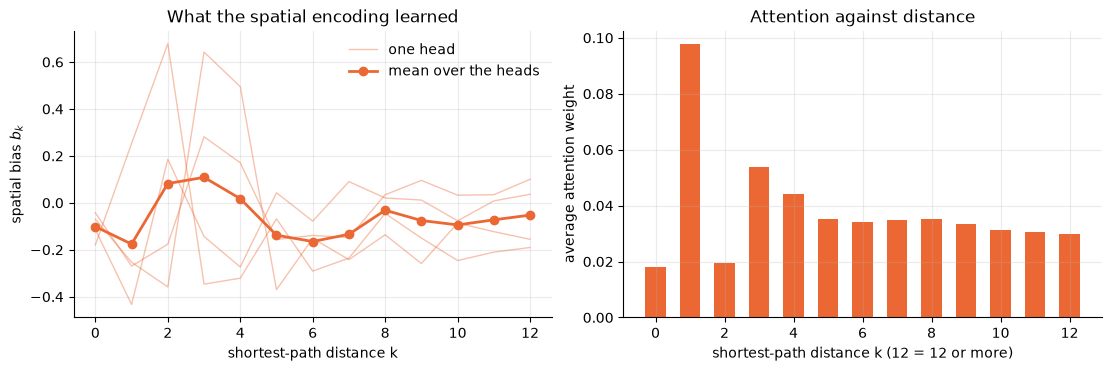

In [36]:
@torch.no_grad()
def attention_by_distance(model, data, max_dist=12):
    """Average attention weight of one (real) atom at distance k, last layer of a model with [VNode]."""
    model.eval()
    total, count = torch.zeros(max_dist + 1), torch.zeros(max_dist + 1)
    for b in data.batches(256):
        model(b)
        alpha = model.layers[-1].attn.alpha.mean(1)[:, 1:, 1:]                      # average over heads, without [VNode]
        d = b.spd.clamp(max=max_dist)[b.allowed]
        total += torch.bincount(d, alpha[b.allowed], minlength=max_dist + 1).cpu()
        count += torch.bincount(d, minlength=max_dist + 1).cpu()
    return (total / count).numpy()

b_k = graphormer.spatial.weight.detach().cpu().numpy()[:13]                         # [distances, heads]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
for head in range(b_k.shape[1]):
    axes[0].plot(b_k[:, head], color=MODEL_COLORS['Graphormer'], lw=1, alpha=0.4, label='one head' if head == 0 else None)
axes[0].plot(b_k.mean(1), 'o-', color=MODEL_COLORS['Graphormer'], lw=2, label='mean over the heads')
axes[0].set(xlabel='shortest-path distance k', ylabel='spatial bias $b_k$', title='What the spatial encoding learned')
axes[0].legend(frameon=False)
axes[1].bar(range(13), attention_by_distance(graphormer, test_set), width=0.6, color=MODEL_COLORS['Graphormer'])
axes[1].set(xlabel='shortest-path distance k (12 = 12 or more)', ylabel='average attention weight',
            title='Attention against distance')
plt.show()


* The attention is far from uniform. An atom gives each bonded neighbour (distance 1) about three times the weight of a far atom, and atoms at distance 2 get as little as the atom itself. Atoms 5 or more bonds away still get about a third of the weight of a neighbour each, and there are many of them: the model really looks at the whole molecule in every layer.
* The peak at distance 1 does not come from the spatial bias alone: averaged over the heads, $b_1$ is even slightly negative, and the heads disagree with each other. The edge encoding $c_{ij}$ and the queries and keys also shape the attention.
* The distances separate graphs that 1-WL cannot, but having the distances does not mean that the model can use them.


# 6. GraphGPS: local + global

Graphormer has to build the whole $N \times N$ attention matrix, because the edge features are inside it. GPS decouples the two jobs. Its recipe has three ingredients: an encoding of the nodes, a local MPNN that reads the real edges, and a global attention that sees the nodes as a set. Each layer runs them in parallel:

$$X_M^{\ell+1}, E^{\ell+1} = \text{MPNN}_e^\ell(X^\ell, E^\ell, A), \qquad X_T^{\ell+1} = \text{GlobalAttn}^\ell(X^\ell), \qquad X^{\ell+1} = \text{MLP}^\ell(X_M^{\ell+1} + X_T^{\ell+1})$$

We take GINE, a plain Transformer and RWSE, a common choice for ZINC. Because the global stream never touches the edges, the Transformer could be replaced by a linear attention such as Performer or BigBird, bringing the cost down from $O(n^2)$ to $O(n + m)$.

In [37]:
class GPSLayer(nn.Module):
    """GPS layer:  X_M = MPNN(X, E, A),  X_T = GlobalAttn(X),  X' = MLP(X_M + X_T),
    with residual connections and BatchNorm as in the GPS code. The edge features stay in the local stream."""
    def __init__(self, dim, heads, local=True, use_global=True):
        super().__init__()
        self.local = GINEConv(dim) if local else None
        self.attn = DenseAttention(dim, heads) if use_global else None
        self.norm_m, self.norm_t, self.norm = nn.BatchNorm1d(dim), nn.BatchNorm1d(dim), nn.BatchNorm1d(dim)
        self.ffn = ffn(dim)

    def forward(self, h, e, b):
        out = 0
        if self.local is not None:
            out = out + self.norm_m(h + self.local(h, e, b.src, b.dst))
        if self.attn is not None:
            out = out + self.norm_t(h + self.attn(to_dense(h, b.mask), b.allowed)[b.mask])
        return self.norm(out + self.ffn(out))


class GPS(GraphModel):
    """GraphGPS with GINE as MPNN and a Transformer as global attention.
    pe chooses the encoding of the input: 'rwse', 'lap', or None. Simplified: fixed edge features."""
    def __init__(self, node_types=28, edge_types=4, out_dim=1, dim=64, num_layers=4, heads=4, k_rw=16, k_lap=8,
                 pe='rwse', local=True, use_global=True):
        super().__init__(node_types, edge_types, out_dim, dim)
        self.pe = pe
        k = {'rwse': k_rw, 'lap': k_lap}.get(pe)
        self.pe_norm, self.pe_lin = (nn.BatchNorm1d(k), nn.Linear(k, dim)) if pe else (None, None)
        self.layers = nn.ModuleList(GPSLayer(dim, heads, local, use_global) for _ in range(num_layers))

    def forward(self, b):
        h, e = self.atom(b.x), self.bond(b.edge_type)
        if self.pe == 'rwse':
            h = h + self.pe_lin(self.pe_norm(b.rwse))
        elif self.pe == 'lap':
            h = h + self.pe_lin(self.pe_norm(random_signs(b.lap, b) if self.training else b.lap))
        for layer in self.layers:
            h = layer(h, e, b)
        return self.predict(sum_pool(h, b))

In [38]:
gps = benchmark('GPS', lambda: GPS())

GPS         | test MAE 0.166 ± 0.003 | 174,309 parameters | 8.5 s/epoch


# 7. TokenGT: nodes and edges as tokens

All the models change the Transformer. TokenGT keeps a standard Transformer and changes the input instead: every node and every edge is one token. To let attention recover the graph, each token is augmented with two kinds of identifiers:

* Node identifiers $P \in \mathbb{R}^{n \times d_p}$: orthonormal vectors, so that $P_u^\top P_v = \delta_{uv}$. A node gets $[X_v, P_v, P_v]$, an edge $(u, v)$ gets $[X_{(u,v)}, P_u, P_v]$: two tokens are incident exactly when they share an identifier.
* Type identifiers: a trainable vector $E_{\mathcal{V}}$ for nodes and $E_{\mathcal{E}}$ for edges.

$P$ can be the Laplacian eigenvectors (of the normalised Laplacian) or orthogonal random features: the rows of a random orthogonal matrix from a QR decomposition. A [graph] token reads out the prediction.

With orthonormal identifiers the graph is really in the tokens, and we can check this: the identifiers of an edge token give back its two end points.

In [39]:
g = 7                                                                               # one test molecule
n = int(test_set.mask[g].sum())
E = test_set.E[g, :n, :n]
dst, src = E.nonzero(as_tuple=True)

identifiers = {'Laplacian eigenvectors': test_set.ids[g, :n, :37],
               'orthogonal random features': torch.linalg.qr(torch.randn(37, 37, device=device))[0][:n]}
for name, P in identifiers.items():
    deviation = (P @ P.T - torch.eye(n, device=device)).abs().max()
    u, v = (P @ P[src].T).argmax(0), (P @ P[dst].T).argmax(0)                       # nearest node to each identifier
    recovered = torch.zeros_like(E).index_put_((v, u), torch.ones_like(u, dtype=E.dtype))
    print(f'{name:<27} | P Pᵀ differs from I by {deviation:.1e} | '
          f'adjacency recovered from {len(src)} edge tokens: {bool((recovered == (E > 0)).all())}')

Laplacian eigenvectors      | P Pᵀ differs from I by 1.2e-07 | adjacency recovered from 48 edge tokens: True
orthogonal random features  | P Pᵀ differs from I by 3.6e-07 | adjacency recovered from 48 edge tokens: True


In [40]:
class TokenGT(GraphModel):
    """TokenGT: a standard Transformer on node and edge tokens, with a [graph] token for the readout.
    An undirected edge gives two directed tokens (u, v) and (v, u), as in the reference code.
    node_id: 'lap' (Laplacian eigenvectors), 'orf' (orthogonal random features) or None."""
    def __init__(self, node_types=28, edge_types=4, out_dim=1, dim=64, num_layers=4, heads=4, d_p=37,
                 node_id='lap', type_id=True):
        super().__init__(node_types, edge_types, out_dim, dim)
        self.d_p, self.node_id = d_p, node_id
        self.type_id = nn.Embedding(2, dim) if type_id else None                     # E_V and E_E
        self.proj = nn.Linear(dim + 2 * d_p + (dim if type_id else 0), dim)          # token-wise embedding
        self.graph_token = nn.Parameter(torch.randn(1, 1, dim))
        self.layers = nn.ModuleList(TransformerLayer(dim, heads) for _ in range(num_layers))
        self.final_norm = nn.LayerNorm(dim)

    def identifiers(self, b):
        """Node identifiers P [n, d_p]."""
        if self.node_id == 'lap':
            return random_signs(b.ids, b) if self.training else b.ids
        if self.node_id == 'orf':
            Q, _ = torch.linalg.qr(torch.randn(b.B, self.d_p, self.d_p, device=b.x.device))
            return Q[:, :b.mask.size(1)][b.mask]
        return torch.zeros(b.n, self.d_p, device=b.x.device)

    def forward(self, b):
        P = self.identifiers(b)
        node_tokens = [self.atom(b.x), P, P]                                         # [X_v, P_v, P_v, E_V]
        edge_tokens = [self.bond(b.edge_type), P[b.src], P[b.dst]]                   # [X_uv, P_u, P_v, E_E]
        if self.type_id is not None:
            node_tokens.append(self.type_id.weight[0].expand(b.n, -1))
            edge_tokens.append(self.type_id.weight[1].expand(len(b.src), -1))
        tokens = self.proj(torch.cat([torch.cat(node_tokens, 1), torch.cat(edge_tokens, 1)]))

        graph_of_token = torch.cat([b.gid, b.gid[b.src]])                            # group the tokens by graph, and pad
        count = torch.bincount(graph_of_token, minlength=b.B)
        real = torch.arange(count.max(), device=count.device)[None] < count[:, None]
        h = to_dense(tokens[graph_of_token.argsort(stable=True)], real)
        h = torch.cat([self.graph_token.expand(b.B, -1, -1), h], 1)                  # [graph] comes first
        real = F.pad(real, (1, 0), value=True)
        allowed = real[:, None] & real[:, :, None]
        for layer in self.layers:
            h = layer(h, allowed)
        return self.predict(self.final_norm(h[:, 0]))


In [41]:
tokengt = benchmark('TokenGT', lambda: TokenGT())

TokenGT     | test MAE 0.612 ± 0.003 | 152,705 parameters | 5.6 s/epoch



TokenGT is far behind the other models, although the cell above shows that its tokens contain the complete graph. The information is there, but nothing in the architecture tells the model to use it: a standard Transformer has to learn from the data that two tokens are incident when their identifiers match. 

# 8. Exphormer: sparse attention on an expander

A dense transformer needs $O(n^2)$ scores in every layer. Exphormer replaces the complete graph by a sparse interaction graph $H$ with $O(|V| + |E|)$ edges, the union of three parts:

1. the local edges $E$ of the input graph,
2. a random expander graph, of constant degree,
3. a few virtual nodes, connected to all the nodes.

Attention runs along the edges of $H$ only. So the model is `EdgeAttention` again, as in GT, with edge types that tell local, expander and virtual edges apart.

## 8.1. Expander graphs

Why would a sparse random graph be a good replacement for the complete graph? A $d$-regular graph has adjacency eigenvalues $d = \lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_n \ge -d$. It is an $\epsilon$-expander if $\max(|\lambda_2|, |\lambda_n|) \le \epsilon d$: all the other eigenvalues are small compared with $d$, as for the complete graph.

We generate a random $d$-regular graph from $d/2$ random permutations, as Exphormer does (`regular_expander`) and we compare it with a ring.

In [42]:
def expander_gap(A, d):
    """ε = max(|λ2|, |λn|) / d of a d-regular graph."""
    lam = np.linalg.eigvalsh(A)
    return max(abs(lam[-2]), abs(lam[0])) / d

n, rng = 1001, np.random.default_rng(0)
ring = csl(n, 1).numpy().astype(float)
graphs = {f'expander, d = {d}': (regular_expander(n, d, rng), d) for d in (4, 8, 16)}

rows = {'ring': {'edges': n, 'ε': expander_gap(ring, 2), 'lower limit 2√(d-1)/d': 1.}}
for name, (A, d) in graphs.items():
    rows[name] = {'edges': d * n // 2, 'ε': expander_gap(A, d), 'lower limit 2√(d-1)/d': 2 * (d - 1) ** 0.5 / d}
rows['complete graph'] = {'edges': n * (n - 1) // 2, 'ε': 1 / (n - 1), 'lower limit 2√(d-1)/d': np.nan}
pd.DataFrame(rows).T.round(3)

,edges,ε,lower limit 2√(d-1)/d
ring,1001.0,1.000,1.000
"expander, d = 4",2002.0,0.868,0.866
"expander, d = 8",4004.0,0.664,0.661
"expander, d = 16",8008.0,0.481,0.484
complete graph,500500.0,0.001,NaN


The ring has $\epsilon \approx 1$: it is no expander at all. A random 4-regular graph already has $\epsilon \approx 0.87$ with only twice as many edges, and $\epsilon$ reaches the best value a $d$-regular graph can have for large $n$ (the Ramanujan limit $2\sqrt{d-1}/d$).

## 8.2. Rapid mixing

In a dense transformer every pair interacts in one layer. In a sparse one, information has to travel. On an expander a random walk forgets its start exponentially fast: the distance to the uniform distribution shrinks by a factor of about $\epsilon$ per step. We start from one node and follow the distribution $\pi^{(t)}$.

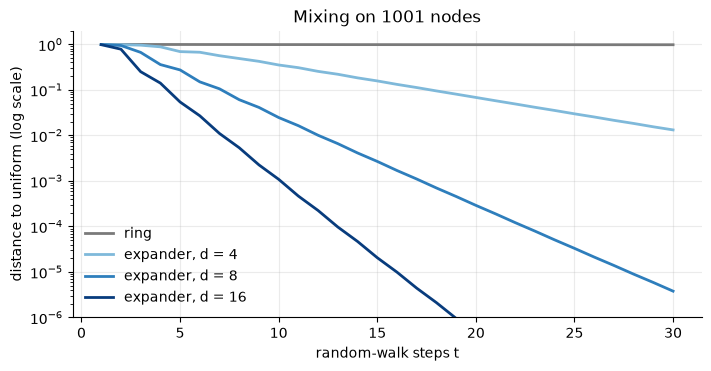

In [43]:
def mixing_curve(A, d, steps=30):
    """Total-variation distance between the random walk from node 0 and the uniform distribution, per step."""
    P, pi, curve = A / d, np.eye(len(A))[0], []
    for _ in range(steps):
        pi = pi @ P
        curve.append(0.5 * np.abs(pi - 1 / len(A)).sum())
    return curve

fig, ax = plt.subplots(figsize=(7, 3.6), constrained_layout=True)
curves = {'ring': (ring, 2, "#7a7a7a")} | {f'expander, d = {d}': (graphs[f'expander, d = {d}'][0], d, plt.cm.Blues(shade))
                                          for d, shade in ((4, 0.45), (8, 0.7), (16, 0.95))}     # darker = larger d
for name, (A, d, color) in curves.items():
    ax.semilogy(range(1, 31), mixing_curve(A, d), lw=2, color=color, label=name)
ax.set(xlabel='random-walk steps t', ylabel='distance to uniform (log scale)', ylim=(1e-6, 2),
       title=f'Mixing on {n} nodes')
ax.legend(frameon=False)
plt.show()

After 30 steps the walk on the ring is still near its start. On the expanders the distance falls in a straight line on the log scale: exponentially fast, and faster for larger $d$.

What does this mean for our molecules? We measure how many hops separate two atoms, in the molecule and after adding each overlay.

In [44]:
def hops(E, real, virtual=False):
    """Largest distance per graph (mean over the graphs) and share of pairs within 4 hops, on the real nodes."""
    N, nodes = real.size(1), real.any(1).long()
    if virtual:                                                                     # the virtual node is the last node
        E = F.pad(E, (0, 1, 0, 1))
        E[:, N, :N], E[:, :N, N] = nodes, nodes
    spd, _ = shortest_paths(E, max_hops=1)
    d = spd[:, :N, :N].masked_fill(~real, 0)
    return {'mean diameter': d.flatten(1).max(1).values.float().mean().item(),
            'pairs within 4 hops (%)': (d[real] <= 4).float().mean().item() * 100}

local = test_set.E.long().cpu()
expander = test_set.exp.long().cpu()
real = real_pairs.cpu()
pd.DataFrame({'molecule': hops(local, real),
              'molecule + expander': hops(local + expander, real),
              'molecule + virtual node': hops(local, real, virtual=True),
              'H (all three)': hops(local + expander, real, virtual=True)}).T.round(1)

,mean diameter,pairs within 4 hops (%)
molecule,12.5,48.9
molecule + expander,3.3,100.0
molecule + virtual node,2.0,100.0
H (all three),2.0,100.0



A molecule has a diameter of 12.5 bonds on average, and only 49 % of the atom pairs are within the reach of a 4-layer GNN. The expander alone brings the diameter down to 3.3 hops, and the virtual node to 2 hops. On $H$, every pair of atoms is within 4 hops, although each atom only attends to a few others.


## 8.3. The model

Exphormer is `GTLayer` on $H$, with RWSE in the input so that it differs from GPS only in *which pairs attend*. The paper also runs an MPNN in parallel; we leave it out, because $H$ contains the local edges.

In [45]:
class Exphormer(GraphModel):
    """Exphormer: the attention of GT, but on the interaction graph H, the union of the
    local edges, a random expander and one virtual node per graph. Every component can be switched off.
    Simplified: no parallel MPNN, RWSE as node encoding."""
    def __init__(self, node_types=28, edge_types=4, out_dim=1, dim=64, num_layers=4, heads=4, k_rw=16,
                 local=True, expander=True, virtual=True):
        super().__init__(node_types, edge_types, out_dim, dim)
        self.local, self.expander, self.virtual = local, expander, virtual
        self.EXPANDER, self.VIRTUAL = edge_types, edge_types + 1          # two extra edge types
        self.bond = nn.Embedding(edge_types + 2, dim)
        self.pe_norm, self.pe_lin = nn.BatchNorm1d(k_rw), nn.Linear(k_rw, dim)
        self.vnode = nn.Parameter(torch.randn(1, dim))
        self.layers = nn.ModuleList(GTLayer(dim, heads, update_edges=False) for _ in range(num_layers))

    def interaction_graph(self, b):
        """Edge list of H: virtual nodes come after the real ones, one per graph."""
        src, dst, types = [], [], []
        if self.local:
            src, dst, types = [b.src], [b.dst], [b.edge_type]
        if self.expander:
            src, dst = src + [b.exp_src], dst + [b.exp_dst]
            types.append(torch.full_like(b.exp_src, self.EXPANDER))
        if self.virtual:
            nodes, virtual = torch.arange(b.n, device=b.x.device), b.n + b.gid
            src, dst = src + [nodes, virtual], dst + [virtual, nodes]
            types.append(torch.full((2 * b.n,), self.VIRTUAL, device=b.x.device))
        return torch.cat(src), torch.cat(dst), torch.cat(types)

    def forward(self, b):
        h = self.atom(b.x) + self.pe_lin(self.pe_norm(b.rwse))
        if self.virtual:
            h = torch.cat([h, self.vnode.expand(b.B, -1)])
        src, dst, types = self.interaction_graph(b)
        e = self.bond(types)
        for layer in self.layers:
            h, e = layer(h, e, src, dst)
        return self.predict(sum_pool(h[:b.n], b))

In [46]:
exphormer = benchmark('Exphormer', lambda: Exphormer())

Exphormer   | test MAE 0.189 ± 0.008 | 157,089 parameters | 5.9 s/epoch


## 8.4. Scaling

Molecules are too small to show the point of Exphormer. On one large graph, we now time one attention step (forward and backward) of the two forms from Section 2. The graph is random, with mean degree 5, and $H$ adds an expander of degree 4 and one virtual node. We stop the dense form at 8,000 nodes.

In [47]:
def timed(step, repeats=3):
    """Median time of step(), in seconds."""
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        step()
        times.append(time.perf_counter() - start)
    return float(np.median(times))

def interaction_edges(n, degree=5, expander_degree=4):
    """Edge list of H on n nodes: a random graph, a random expander and a virtual node (node n)."""
    u = torch.randint(0, n, (degree * n // 2,))
    v = torch.randint(0, n, (degree * n // 2,))
    perms = [torch.randperm(n) for _ in range(expander_degree // 2)]
    a = torch.cat([u, *[torch.arange(n) for _ in perms], torch.arange(n)])
    b = torch.cat([v, *perms, torch.full((n,), n)])
    return torch.cat([a, b]), torch.cat([b, a])

def sparse_step(attn, h, src, dst):
    attn(h, src, dst)[0].sum().backward()

def dense_step(attn, h, allowed):
    attn(h, allowed).sum().backward()

dim, heads = 64, 4
dense_attn, edge_attn = DenseAttention(dim, heads), EdgeAttention(dim, heads)
sizes, dense_times, edge_times, dense_pairs, edge_pairs = [1000, 2000, 4000, 8000, 16000, 32000, 64000], [], [], [], []
for n in sizes:
    src, dst = interaction_edges(n)
    h = torch.randn(n + 1, dim)
    edge_times.append(timed(lambda: sparse_step(edge_attn, h, src, dst)))
    edge_pairs.append(len(src))
    if n <= 8000:
        allowed = torch.ones(1, n, n, dtype=torch.bool)
        dense_times.append(timed(lambda: dense_step(dense_attn, h[None, :n], allowed)))
        dense_pairs.append(n ** 2)

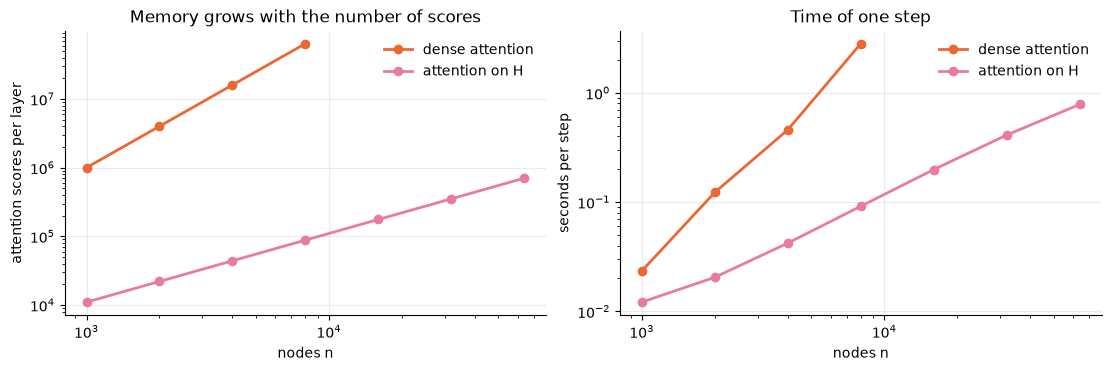

Slope on the log-log plot: dense 2.26, H 1.06  (2 = quadratic, 1 = linear)
At n = 64,000, H has 704,000 edges, the complete graph 4,096,000,000


In [48]:
slope = lambda x, y: np.polyfit(np.log(x), np.log(y), 1)[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
n_dense = sizes[:len(dense_times)]
for ax, (y_dense, y_edge, label) in zip(axes, [(dense_pairs, edge_pairs, 'attention scores per layer'),
                                               (dense_times, edge_times, 'seconds per step')]):
    ax.loglog(n_dense, y_dense, 'o-', lw=2, color=MODEL_COLORS['Graphormer'], label='dense attention')
    ax.loglog(sizes, y_edge, 'o-', lw=2, color=MODEL_COLORS['Exphormer'], label='attention on H')
    ax.set(xlabel='nodes n', ylabel=label)
    ax.legend(frameon=False)
axes[0].set_title('Memory grows with the number of scores')
axes[1].set_title('Time of one step')
plt.show()
print(f'Slope on the log-log plot: dense {slope(n_dense[1:], dense_times[1:]):.2f}, H {slope(sizes[1:], edge_times[1:]):.2f}'
      f'  (2 = quadratic, 1 = linear)')
print(f'At n = {sizes[-1]:,}, H has {edge_pairs[-1]:,} edges, the complete graph {sizes[-1] ** 2:,}')


* The number of scores is quadratic for the dense form and linear for $H$: at 64,000 nodes, $H$ has about 5,800 times fewer.
* The time follows, with slopes close to 2 and 1. At 1,000 nodes the two forms cost about the same, because $H$ stores a whole vector per edge where the dense form stores one number per pair. The gain only appears on larger graphs: at 8,000 nodes, $H$ is about 10 times faster.
* At 64,000 nodes one dense attention matrix would need 65 GB (4.1 billion pairs, 4 heads, 4 bytes), so the dense form would not even fit in memory. This is the point of slide 65.


# 9. HGT: heterogeneous graphs

All the graphs had one kind of node. Real networks often have several: an academic graph has authors, papers, terms and conferences. HGT makes the attention depend on the types, without any manually chosen meta-paths. Every interaction belongs to a meta relation $\langle \tau(s), \phi(e), \tau(t) \rangle$: the type of the source, of the edge and of the target. One layer has three steps:

1. Heterogeneous mutual attention. Keys and queries use one linear map per node type. A matrix per edge type sits between them, and a scalar $\mu$ gives the prior importance of the meta relation:

$$K^i(s) = \text{K-Linear}^i_{\tau(s)}\big(H^{(l-1)}[s]\big), \qquad Q^i(t) = \text{Q-Linear}^i_{\tau(t)}\big(H^{(l-1)}[t]\big)$$

$$\text{ATT-head}^i(s, e, t) = \big(K^i(s)\, W_{ATT}^{\phi(e)}\, Q^i(t)^\top\big) \cdot \frac{\mu_{\langle \tau(s), \phi(e), \tau(t) \rangle}}{\sqrt{d}}, 


\qquad \text{Attention}(s, e, t) = \text{Softmax}_{\forall s \in N(t)}\Big(\big\Vert_{i}\, \text{ATT-head}^i(s, e, t)\Big)$$

2. Heterogeneous message passing. Values use one linear map per source type, and a matrix per edge type:

$$\text{Message}(s, e, t) = \big\Vert_{i}\; \text{V-Linear}^i_{\tau(s)}\big(H^{(l-1)}[s]\big)\, W_{MSG}^{\phi(e)}$$

3. Target-specific aggregation. The messages are summed with the attention weights, go through a linear map of the target type, and a residual connection closes the layer:

$$H^{(l)}[t] = \text{A-Linear}_{\tau(t)}\Big(\sigma\big(\sum_{\forall s \in N(t)} \text{Attention}(s, e, t) \cdot \text{Message}(s, e, t)\big)\Big) + H^{(l-1)}[t]$$

In [36]:
def load_hetero(dataset_class, name, target):
    """Dense features and one edge list per meta relation of a heterogeneous dataset."""
    with contextlib.redirect_stderr(io.StringIO()), contextlib.redirect_stdout(io.StringIO()):
        data = dataset_class(f"{ROOT}/{name}")[0]
    g = SimpleNamespace(name=name, target=target, node_types=list(data.node_types))
    g.num_nodes = {t: data[t].num_nodes for t in g.node_types}
    g.x = {t: data[t].x.float().to(device) for t in g.node_types if 'x' in data[t]}
    g.edges = {rel: tuple(data[rel].edge_index.to(device)) for rel in data.edge_types}
    g.y = data[target].y.to(device)
    g.C = int(g.y.max()) + 1
    g.masks = tuple(data[target][f'{m}_mask'].to(device) for m in ('train', 'val', 'test'))
    return g

In [37]:
dblp = load_hetero(DBLP, 'DBLP', 'author')
print('Nodes:', dblp.num_nodes)
print('Features:', {t: x.shape[1] for t, x in dblp.x.items()})
for (s, _, t), (src, _) in dblp.edges.items():
    print(f'  {s:>10} -> {t:<10} {len(src):>6} edges')
print('Train / val / test authors:', [int(m.sum()) for m in dblp.masks])

Nodes: {'author': 4057, 'paper': 14328, 'term': 7723, 'conference': 20}
Features: {'author': 334, 'paper': 4231, 'term': 50}
      author -> paper       19645 edges
       paper -> author      19645 edges
       paper -> term        85810 edges
       paper -> conference  14328 edges
        term -> paper       85810 edges
  conference -> paper       14328 edges
Train / val / test authors: [400, 400, 3257]


In [ ]:
class HGTLayer(nn.Module):
    """HGT layer. For a meta relation <τ(s), φ(e), τ(t)> and a head i:
        ATT-head^i(s, e, t) = (K^i(s) W_ATT^φ(e) Q^i(t)^T) · μ_<τ(s),φ(e),τ(t)> / sqrt(d)
        Message^i(s, e, t)  = V^i(s) W_MSG^φ(e)
    The softmax runs over all incoming edges of t, whatever their meta relation. In PyG every edge type of these
    datasets is called 'to', so each meta relation is its own φ(e). The flags remove the type-dependent parts."""
    def __init__(self, node_types, relations, dim, heads, dropout=0.5,
                 typed_nodes=True, use_w_att=True, use_w_msg=True, use_mu=True):
        super().__init__()
        self.H, self.d, self.dropout, self.typed_nodes = heads, dim // heads, dropout, typed_nodes
        linears = lambda: nn.ModuleDict({t: nn.Linear(dim, dim) for t in (node_types if typed_nodes else ['all'])})
        self.K, self.Q, self.V, self.A = linears(), linears(), linears(), linears()
        self.norm = nn.ModuleDict({t: nn.LayerNorm(dim) for t in node_types})
        names = ['__'.join(rel) for rel in relations]
        matrices = lambda: nn.ParameterDict({r: nn.Parameter(torch.eye(self.d).repeat(heads, 1, 1)) for r in names})
        self.W_att, self.W_msg = matrices() if use_w_att else None, matrices() if use_w_msg else None
        self.mu = nn.ParameterDict({r: nn.Parameter(torch.ones(1)) for r in names}) if use_mu else None

    def project(self, linear, h):
        return {t: linear[t if self.typed_nodes else 'all'](x).view(-1, self.H, self.d) for t, x in h.items()}

    def forward(self, h, edges):
        K, Q, V = self.project(self.K, h), self.project(self.Q, h), self.project(self.V, h)
        incoming = {t: [] for t in h}
        for rel, (src, dst) in edges.items():
            s, _, t = rel
            r = '__'.join(rel)
            k, v = K[s][src], V[s][src]                                              # [E, H, d]
            if self.W_att is not None:
                k = torch.einsum('ehd,hdf->ehf', k, self.W_att[r])
            if self.W_msg is not None:
                v = torch.einsum('ehd,hdf->ehf', v, self.W_msg[r])
            score = (k * Q[t][dst]).sum(-1) / self.d ** 0.5                          # [E, H]
            incoming[t].append((rel, score * self.mu[r] if self.mu is not None else score, v, dst))
        new, self.share = {}, {}
        for t, x in h.items():
            rels, scores, messages, dsts = zip(*incoming[t])
            dst = torch.cat(dsts)
            alpha = edge_softmax(torch.cat(scores), dst, len(x))                     # attention over all sources of t
            mixed = torch.zeros(len(x), self.H, self.d, device=x.device)
            mixed = mixed.index_add_(0, dst, alpha[..., None] * torch.cat(messages))
            mixed = F.dropout(F.elu(mixed.flatten(1)), self.dropout, self.training)
            new[t] = self.norm[t](x + self.A[t if self.typed_nodes else 'all'](mixed))
            for rel, part in zip(rels, alpha.detach().split([len(d) for d in dsts])):   # share of the attention of t
                self.share[rel] = part.sum().item() / self.H / len(x)
        return new


class HGT(nn.Module):
    """Heterogeneous Graph Transformer (Hu et al., 2020) for full-batch node classification.
    Simplified: no relative temporal encoding and no HGSampling. Types without features get free embeddings."""
    def __init__(self, g, dim=64, num_layers=2, heads=4, dropout=0.5, **flags):
        super().__init__()
        self.dropout = dropout
        self.inp = nn.ModuleDict({t: nn.Linear(x.size(1), dim) for t, x in g.x.items()})
        self.free = nn.ParameterDict({t: nn.Parameter(torch.randn(n, dim)) for t, n in g.num_nodes.items() if t not in g.x})
        self.layers = nn.ModuleList(HGTLayer(g.node_types, list(g.edges), dim, heads, dropout, **flags)
                                    for _ in range(num_layers))
        self.out = nn.Linear(dim, g.C)

    def forward(self, g):
        h = {t: self.inp[t](x) for t, x in g.x.items()} | dict(self.free)
        h = {t: F.dropout(x, self.dropout, self.training) for t, x in h.items()}
        for layer in self.layers:
            h = layer(h, g.edges)
        return self.out(F.dropout(h[g.target], self.dropout, self.training))


class MLP(nn.Module):
    """Baseline: only the features of the target nodes."""
    def __init__(self, g, dim=64, dropout=0.5):
        super().__init__()
        self.net = nn.Sequential(nn.Dropout(dropout), nn.Linear(g.x[g.target].size(1), dim), nn.ReLU(),
                                 nn.Dropout(dropout), nn.Linear(dim, g.C))

    def forward(self, g):
        return self.net(g.x[g.target])

In [39]:
def train_hetero(model, g, epochs=300, lr=1e-3, weight_decay=1e-3, patience=100):
    """Full-batch training with early stopping on the validation accuracy. Returns (test accuracy, s/epoch)."""
    model = model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    tr, va, te = g.masks
    best_val, best_test, bad, start = 0., 0., 0, time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        loss = F.cross_entropy(model(g)[tr], g.y[tr])
        opt.zero_grad()
        loss.backward()
        opt.step()
        model.eval()
        with torch.no_grad():
            pred = model(g).argmax(1)
        val, test = ((pred[m] == g.y[m]).float().mean().item() for m in (va, te))
        if val > best_val:
            best_val, best_test, bad, best_state = val, test, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
        if bad >= patience:
            break
    model.load_state_dict(best_state)
    return best_test, (time.time() - start) / epoch

def benchmark_hetero(name, make_model, g, seeds=None, table=None):
    """Train make_model() with every seed on g; store and print the mean ± std test accuracy."""
    accs = []
    for seed in (seeds or SEEDS):
        set_seed(seed)
        model = make_model()
        acc, seconds = train_hetero(model, g)
        accs.append(acc)
    if table is not None:
        table[(name, g.name)] = np.array(accs)
    print(f"{g.name:<5} {name:<24} | test accuracy {np.mean(accs) * 100:5.1f} ± {np.std(accs) * 100:.1f} % | "
          f"{seconds:.2f} s/epoch")
    return model

def relation_table(layer, g):
    """For one trained HGT layer: μ of each meta relation, its share of the attention of the target, and its share of
    the edges into the target. The last two are equal if the attention treats all the neighbours alike."""
    into = {t: sum(len(src) for (_, _, b), (src, _) in g.edges.items() if b == t) for t in g.node_types}
    rows = {f'{s} -> {t}': {'μ': layer.mu['__'.join((s, r, t))].item(), 'share of the attention': layer.share[(s, r, t)],
                            'share of the edges': len(g.edges[(s, r, t)][0]) / into[t]} for s, r, t in g.edges}
    return pd.DataFrame(rows).T.sort_index(key=lambda idx: [i.split(' -> ')[1] for i in idx]).round(3)

We compare HGT with an MLP on the features of the authors, and with the same model without any type information: all the types share one set of K, Q, V and A maps, and there is no $W_{ATT}$, $W_{MSG}$ or $\mu$. This last model is a plain graph transformer on the type-blind graph.

In [40]:
dblp_results = {}
benchmark_hetero('MLP', lambda: MLP(dblp), dblp, table=dblp_results)
benchmark_hetero('HGT without types', lambda: HGT(dblp, typed_nodes=False, use_w_att=False, use_w_msg=False, use_mu=False),
                 dblp, table=dblp_results)
hgt = benchmark_hetero('HGT', lambda: HGT(dblp), dblp, table=dblp_results)

DBLP  MLP                      | test accuracy  78.8 ± 0.1 % | 0.01 s/epoch


DBLP  HGT without types        | test accuracy  90.2 ± 0.3 % | 0.05 s/epoch


DBLP  HGT                      | test accuracy  91.9 ± 0.5 % | 0.08 s/epoch


The attention can tell us which relations matter. For the trained model we read two numbers per meta relation: the learned $\mu$, and the share of the attention of a target that goes to this relation. We compare this share with the share of the edges of the relation: if they are equal, the attention treats all the neighbours alike. We read the first layer: with 2 layers, the only relation of the last layer that reaches the prediction is paper -> author, so the others receive no gradient there.

In [41]:
hgt.eval()
with torch.no_grad():
    hgt(dblp)
relation_table(hgt.layers[0], dblp)

,μ,share of the attention,share of the edges
paper -> author,1.057,1.000,1.000
paper -> conference,1.000,1.000,1.000
author -> paper,1.061,0.177,0.164
term -> paper,1.025,0.682,0.716
conference -> paper,1.027,0.141,0.120
paper -> term,1.000,1.000,1.000



* The graph brings most of the gain: the two graph models are 11 to 13 points above the MLP. The papers of an author, and the terms of these papers, say more about the research area than the author's own features.
* The types add another 1.7 points.
* This gain does not come from $\mu$ or from a preference for one relation. $\mu$ stays close to its starting value of 1, and the attention of a paper is divided almost like its edges: terms get 68 % of the attention for 72 % of the edges, while authors and conferences get slightly more than their share. So the gain probably comes from the type-specific maps.
* $\mu$ of paper -> term and paper -> conference stays at exactly 1: their updates would need a third layer to reach the authors, so they receive no gradient.


# 10. Summary

In [42]:
n = test_set.mask.sum(1).float()
m = (test_set.E > 0).sum((1, 2)).float()                                            # directed edges
h = m + test_set.exp.sum((1, 2)) + 2 * n                                            # directed edges of H
scores = {'GINE': m, 'GT': m, 'Graphormer': (n + 1) ** 2, 'GPS': m + n ** 2, 'TokenGT': (n + m + 1) ** 2, 'Exphormer': h}

summary = pd.DataFrame({name: {'test MAE': f"{r['test'].mean():.3f} ± {r['test'].std():.3f}",
                               'parameters': f"{r['params']:,}", 's/epoch': round(r['seconds'], 1),
                               'scores per molecule': int(scores[name].mean())}
                        for name, r in RESULTS.items()}).T
summary

,test MAE,parameters,s/epoch,scores per molecule
GINE,0.323 ± 0.003,"40,069",3.0,49
GT,0.391 ± 0.004,"240,321",6.0,49
Graphormer,0.392 ± 0.032,"140,489",7.5,601
GPS,0.164 ± 0.004,"174,309",6.9,603
TokenGT,0.613 ± 0.003,"152,705",4.7,5671
Exphormer,0.187 ± 0.005,"157,089",5.5,178


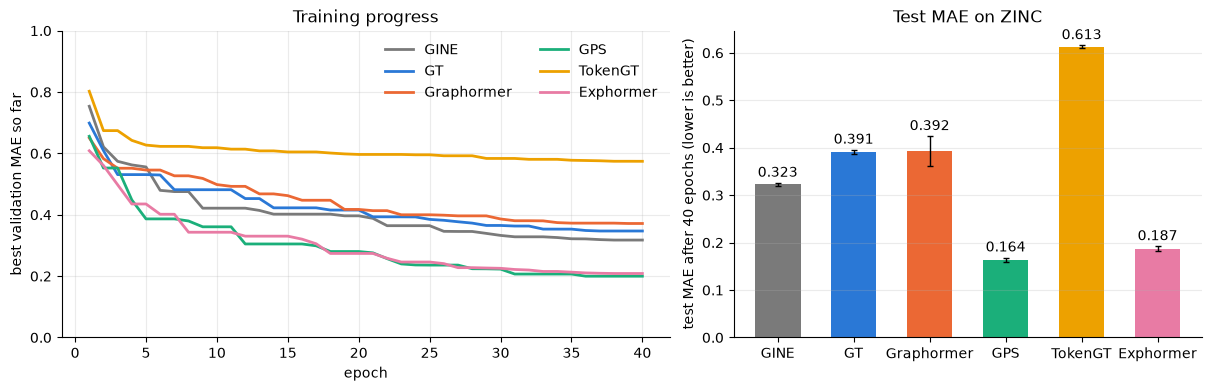

In [ ]:
names = list(RESULTS)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True, gridspec_kw={'width_ratios': [1.3, 1]})
for name in names:
    axes[0].plot(range(1, len(RESULTS[name]['val']) + 1), np.minimum.accumulate(RESULTS[name]['val']), lw=2,
                 color=MODEL_COLORS[name], label=name)
axes[0].set(xlabel='epoch', ylabel='best validation MAE', title='Training progress', ylim=(0, 1))
axes[0].legend(frameon=False, ncol=2)
bars = axes[1].bar(names, [RESULTS[n]['test'].mean() for n in names], yerr=[RESULTS[n]['test'].std() for n in names],
                   width=0.6, color=[MODEL_COLORS[n] for n in names], error_kw=dict(lw=1, capsize=2))
axes[1].bar_label(bars, fmt='%.3f', padding=2)
axes[1].set(ylabel=f'test MAE after {EPOCHS} epochs (lower is better)', title='Test MAE on ZINC')
axes[1].grid(axis='x', visible=False)
plt.show()